# DeepCare 05: Evaluation

Works entirely from the validation and test probabilities saved by notebooks 03 and 04, so nothing is retrained.

1. **ROC and PR curves** for all four models
2. **Bootstrap confidence intervals**, including *paired* differences against XGBoost, to see which gaps are real
3. **Operating points**: thresholds chosen on the validation set to hit a target recall (70/80/90%), with test-set precision, specificity and the number of people flagged per true case found
4. **Confusion matrices** at the 80% recall operating point
5. **Calibration**: reliability diagrams, Brier score and expected calibration error (ECE), before and after post-hoc calibration fitted on the validation set

The test set is only used for reporting. Every threshold and calibrator is fitted on validation data.

## 1. Setup and load saved probabilities

In [8]:
import os, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, brier_score_loss, f1_score)
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from google.colab import drive
drive.mount('/content/drive')

SEED = 42
N_BOOT = 1500                       # bootstrap resamples (raise to 1000+ for the final report)
PROJECT_DIR = '/content/drive/MyDrive/deepcare'
R = f'{PROJECT_DIR}/results'
MODELS = ['logreg', 'random_forest', 'xgboost', 'mlp']
LABEL = {'logreg': 'Logistic Regression', 'random_forest': 'Random Forest', 'xgboost': 'XGBoost', 'mlp': 'Keras MLP'}

P = {}
for m in MODELS:
    z = np.load(f'{R}/probs_{m}.npz')
    P[m] = {'val': z['val'], 'test': z['test']}
    yva, yte = z['val_y'].astype(int), z['test_y'].astype(int)     # identical for every model (checked below)
for m in MODELS:
    z = np.load(f'{R}/probs_{m}.npz')
    assert np.array_equal(z['val_y'].astype(int), yva) and np.array_equal(z['test_y'].astype(int), yte)

print('val:', len(yva), '| test:', len(yte), '| test prevalence:', round(yte.mean(), 4))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
val: 34421 | test: 34422 | test prevalence: 0.153


## 2. ROC and precision-recall curves (test set)

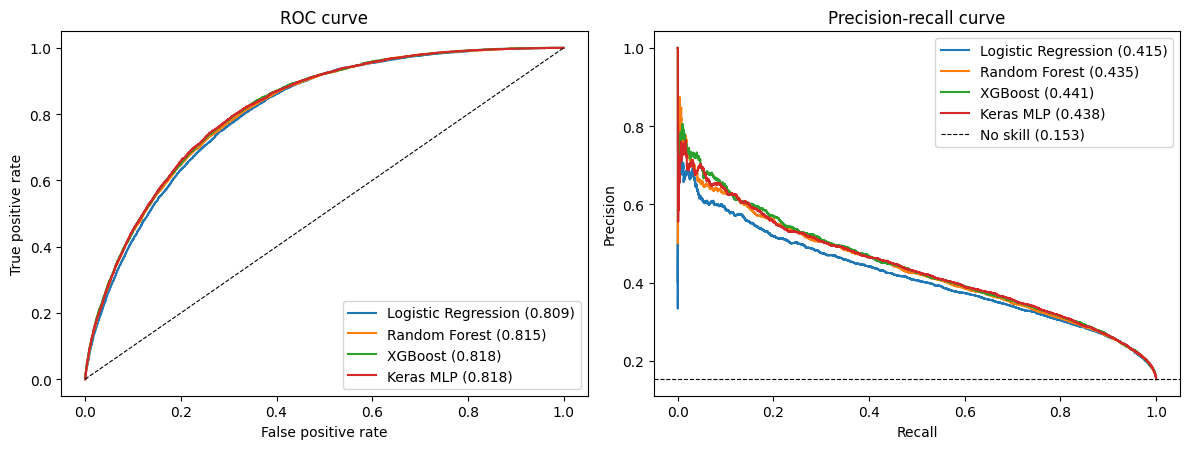

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for m in MODELS:
    fpr, tpr, _ = roc_curve(yte, P[m]['test'])
    ax[0].plot(fpr, tpr, label=f"{LABEL[m]} ({roc_auc_score(yte, P[m]['test']):.3f})")
    prec, rec, _ = precision_recall_curve(yte, P[m]['test'])
    ax[1].plot(rec, prec, label=f"{LABEL[m]} ({average_precision_score(yte, P[m]['test']):.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[0].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate')
ax[1].axhline(yte.mean(), color='k', ls='--', lw=0.8, label=f'No skill ({yte.mean():.3f})')
ax[1].set(title='Precision-recall curve', xlabel='Recall', ylabel='Precision')
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{R}/curves_roc_pr.png', dpi=150); plt.show()

## 3. Bootstrap confidence intervals

Test rows are resampled with replacement; **every model is scored on the same resamples**, so differences between models are paired. If the 95% interval of a paired difference includes 0, the models cannot be separated on this test set.

In [10]:
rng = np.random.default_rng(SEED)
n = len(yte)
boot = {m: {'roc_auc': [], 'pr_auc': []} for m in MODELS}
for b in range(N_BOOT):
    idx = rng.integers(0, n, n)
    yb = yte[idx]
    if yb.min() == yb.max():
        continue
    for m in MODELS:
        pb = P[m]['test'][idx]
        boot[m]['roc_auc'].append(roc_auc_score(yb, pb))
        boot[m]['pr_auc'].append(average_precision_score(yb, pb))
boot = {m: {k: np.array(v) for k, v in d.items()} for m, d in boot.items()}

def ci(a): return np.percentile(a, [2.5, 97.5])
rows = []
for m in MODELS:
    r = {'model': m}
    for k, f in [('roc_auc', roc_auc_score), ('pr_auc', average_precision_score)]:
        lo, hi = ci(boot[m][k])
        r[k] = f(yte, P[m]['test']); r[f'{k}_lo'] = lo; r[f'{k}_hi'] = hi
    rows.append(r)
ci_table = pd.DataFrame(rows).set_index('model')
display(ci_table.round(4))

print('\nPaired differences vs XGBoost (model minus XGBoost):')
drows = []
for m in [x for x in MODELS if x != 'xgboost']:
    for k in ['roc_auc', 'pr_auc']:
        d = boot[m][k] - boot['xgboost'][k]
        lo, hi = ci(d)
        drows.append({'model': m, 'metric': k, 'mean_diff': d.mean(), 'ci_lo': lo, 'ci_hi': hi,
                      'separable': not (lo <= 0 <= hi)})
diff_table = pd.DataFrame(drows)
display(diff_table.round(4))
ci_table.to_csv(f'{R}/bootstrap_ci.csv'); diff_table.to_csv(f'{R}/bootstrap_paired_diffs.csv', index=False)

,roc_auc,roc_auc_lo,roc_auc_hi,pr_auc,pr_auc_lo,pr_auc_hi
model,,,,,,
logreg,0.8085,0.8028,0.8141,0.4147,0.4017,0.4291
random_forest,0.8150,0.8092,0.8207,0.4348,0.4212,0.4489
xgboost,0.8177,0.8120,0.8233,0.4409,0.4271,0.4552
mlp,0.8177,0.8118,0.8236,0.4377,0.4240,0.4518



Paired differences vs XGBoost (model minus XGBoost):


,model,metric,mean_diff,ci_lo,ci_hi,separable
0,logreg,roc_auc,-0.0092,-0.0108,-0.0074,True
1,logreg,pr_auc,-0.0260,-0.0317,-0.0205,True
2,random_forest,roc_auc,-0.0027,-0.0040,-0.0014,True
3,random_forest,pr_auc,-0.0060,-0.0097,-0.0019,True
4,mlp,roc_auc,0.0001,-0.0011,0.0011,False
5,mlp,pr_auc,-0.0031,-0.0066,0.0003,False


## 4. Operating points for screening

For each target recall, the threshold is the **highest** validation threshold that still reaches that recall, then applied unchanged to the test set. *Flagged per case found* is 1/precision: how many people are flagged for each true case caught.

In [11]:
def threshold_for_recall(y, p, target):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return float(thr[ok[-1]]) if len(ok) else float(thr[0])

def at_threshold(y, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if (tp + fp) else np.nan
    return {'threshold': round(t, 4), 'recall': tp / (tp + fn), 'precision': prec,
            'specificity': tn / (tn + fp), 'f1': f1_score(y, pred),
            'flagged_share': (tp + fp) / len(y), 'flagged_per_case_found': 1 / prec if prec else np.nan,
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}

op_rows = []
for target in [0.70, 0.80, 0.90]:
    for m in MODELS:
        t = threshold_for_recall(yva, P[m]['val'], target)
        op_rows.append({'target_recall': target, 'model': m, **at_threshold(yte, P[m]['test'], t)})
op = pd.DataFrame(op_rows)
show = ['target_recall', 'model', 'threshold', 'recall', 'precision', 'specificity', 'flagged_share', 'flagged_per_case_found']
display(op[show].round(3))
op.to_csv(f'{R}/operating_points.csv', index=False)

,target_recall,model,threshold,recall,precision,specificity,flagged_share,flagged_per_case_found
0,0.7,logreg,0.557,0.691,0.343,0.761,0.309,2.919
1,0.7,random_forest,0.553,0.696,0.350,0.767,0.304,2.859
2,0.7,xgboost,0.582,0.697,0.354,0.770,0.301,2.825
3,0.7,mlp,0.590,0.700,0.357,0.772,0.300,2.802
4,0.8,logreg,0.466,0.796,0.305,0.672,0.399,3.280
5,0.8,random_forest,0.476,0.801,0.309,0.676,0.397,3.237
6,0.8,xgboost,0.498,0.798,0.315,0.687,0.387,3.171
7,0.8,mlp,0.507,0.799,0.316,0.687,0.387,3.168
8,0.9,logreg,0.344,0.902,0.260,0.537,0.530,3.845
9,0.9,random_forest,0.363,0.901,0.262,0.541,0.527,3.820


## 5. Confusion matrices at the 80% recall operating point

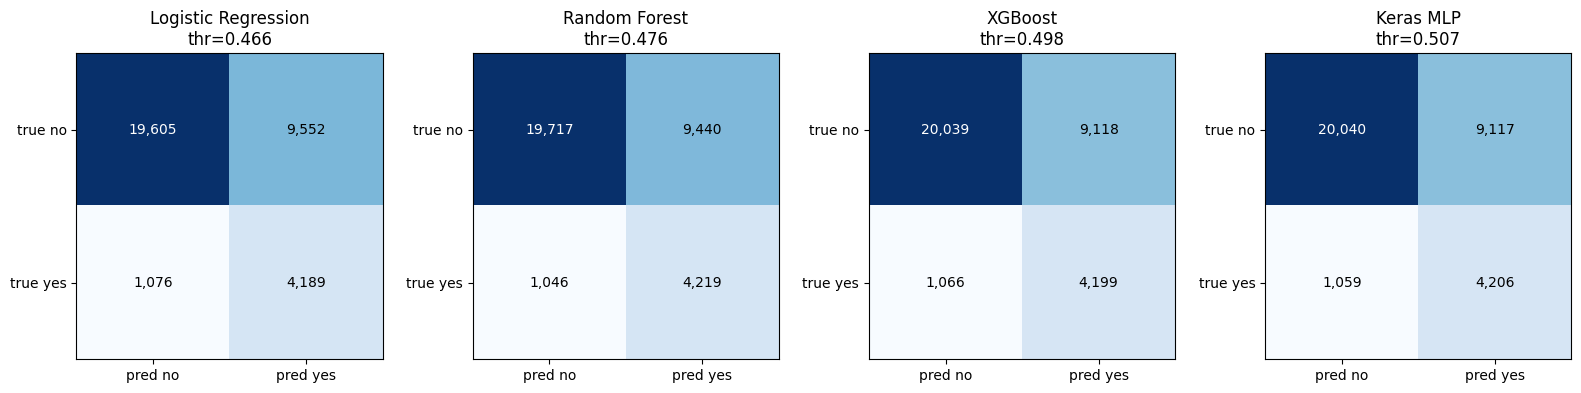

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, m in zip(ax, MODELS):
    r = op[(op.target_recall == 0.80) & (op.model == m)].iloc[0]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    a.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        a.text(j, i, f'{v:,}', ha='center', va='center', color='white' if v > cm.max() / 2 else 'black')
    a.set(title=f'{LABEL[m]}\nthr={r.threshold:.3f}', xticks=[0, 1], yticks=[0, 1],
          xticklabels=['pred no', 'pred yes'], yticklabels=['true no', 'true yes'])
plt.tight_layout(); plt.savefig(f'{R}/confusion_matrices_recall80.png', dpi=150); plt.show()

## 6. Calibration

The class-weighted models output inflated probabilities, so raw scores are not risk estimates. Two post-hoc calibrators are fitted on the **validation** probabilities and scored on the test set:

- **Platt scaling**: logistic regression on the logit of the score (smooth, monotone)
- **Isotonic regression**: flexible, monotone step function

Calibration changes the probabilities but barely affects ranking metrics (AUC). It matters for the demo app, which should show a meaningful risk percentage.

In [13]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p)).reshape(-1, 1)

def ece(y, p, bins=10):
    d = pd.DataFrame({'y': y, 'p': p})
    d['b'] = pd.qcut(d['p'], bins, duplicates='drop')
    g = d.groupby('b', observed=True).agg(n=('y', 'size'), obs=('y', 'mean'), pred=('p', 'mean'))
    return float((g['n'] / g['n'].sum() * (g['obs'] - g['pred']).abs()).sum())

calibrators, P_cal, cal_rows = {}, {}, []
for m in MODELS:
    platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(P[m]['val']), yva)
    iso = IsotonicRegression(out_of_bounds='clip').fit(P[m]['val'], yva)
    calibrators[m] = {'platt': platt, 'isotonic': iso}
    P_cal[m] = {'raw': P[m]['test'],
                'platt': platt.predict_proba(logit(P[m]['test']))[:, 1],
                'isotonic': iso.predict(P[m]['test'])}
    for kind, p in P_cal[m].items():
        cal_rows.append({'model': m, 'version': kind, 'brier': brier_score_loss(yte, p), 'ece': ece(yte, p),
                         'mean_pred': p.mean(), 'roc_auc': roc_auc_score(yte, p)})
cal = pd.DataFrame(cal_rows)
print('observed test prevalence:', round(yte.mean(), 4))
display(cal.round(4))
cal.to_csv(f'{R}/calibration_summary.csv', index=False)
joblib.dump(calibrators, f'{R}/calibrators.joblib')
np.savez(f'{R}/probs_test_calibrated.npz', **{f'{m}_{k}': v for m in MODELS for k, v in P_cal[m].items()}, y=yte)

observed test prevalence: 0.153


,model,version,brier,ece,mean_pred,roc_auc
0,logreg,raw,0.1854,0.2513,0.4042,0.8085
1,logreg,platt,0.1078,0.0151,0.1532,0.8085
2,logreg,isotonic,0.1076,0.0055,0.1534,0.8081
3,random_forest,raw,0.1782,0.2432,0.3961,0.8150
4,random_forest,platt,0.1058,0.0040,0.1539,0.8150
5,random_forest,isotonic,0.1059,0.0034,0.1538,0.8145
6,xgboost,raw,0.1834,0.2444,0.3974,0.8177
7,xgboost,platt,0.1052,0.0043,0.1532,0.8177
8,xgboost,isotonic,0.1053,0.0033,0.1531,0.8177
9,mlp,raw,0.1868,0.2519,0.4048,0.8177


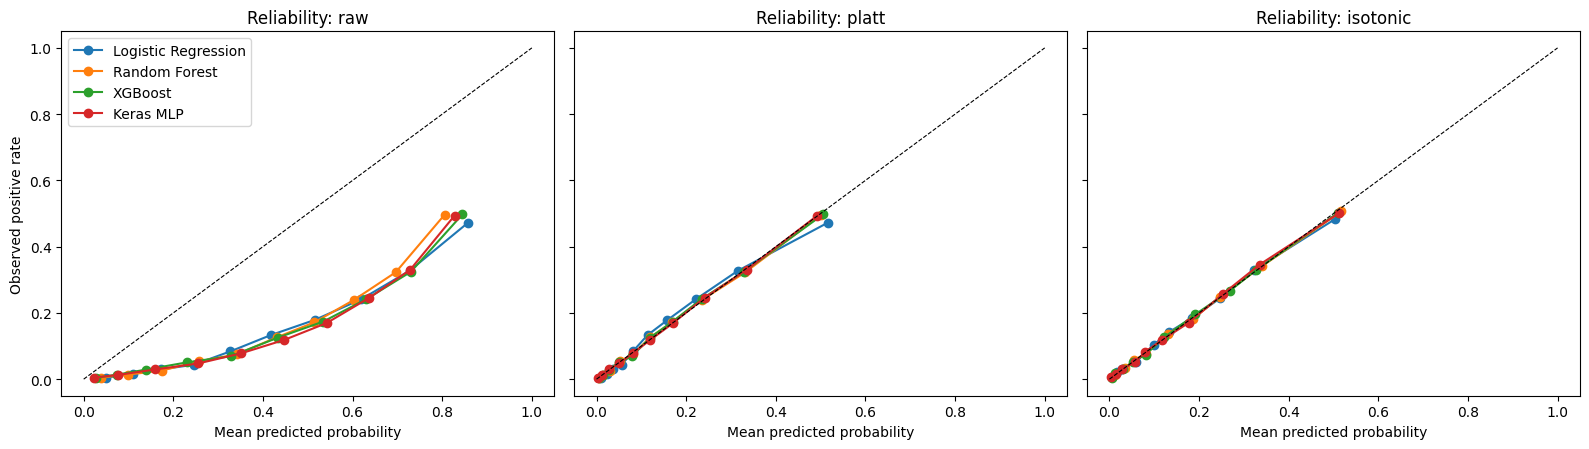

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for a, kind in zip(ax, ['raw', 'platt', 'isotonic']):
    for m in MODELS:
        d = pd.DataFrame({'y': yte, 'p': P_cal[m][kind]})
        d['b'] = pd.qcut(d['p'], 10, duplicates='drop')
        g = d.groupby('b', observed=True).agg(obs=('y', 'mean'), pred=('p', 'mean'))
        a.plot(g['pred'], g['obs'], marker='o', label=LABEL[m])
    a.plot([0, 1], [0, 1], 'k--', lw=0.8)
    a.set(title=f'Reliability: {kind}', xlabel='Mean predicted probability')
ax[0].set_ylabel('Observed positive rate'); ax[0].legend()
plt.tight_layout(); plt.savefig(f'{R}/calibration_reliability.png', dpi=150); plt.show()